# 第 10 步：波动率与相对成交量因子

<!-- SNAPSHOT_NOTE -->

## 数据准备

本页记录完整快照上的实际运行。从 GitHub 克隆源码后，先在仓库根目录运行 `python publication/restore_snapshot.py`，恢复同版本的 `data/` 与 `runs/`，再执行本步。[完整数据与大型结果索引](../../publication/ASSET_INDEX.md)保留全部路径和哈希；本页图表与 Notebook 已保存输出可直接阅读。

## 目标与前置

前面已经完成原始动量的计算、Rank IC 和五分组检验。本步将因子表从一列扩展成三列：20 期动量、20 期日收益波动率、5 期均量相对 20 期均量。先明确各个量的数学含义、单位和时间窗口，再进入下一步的预处理与合成。

本步负责计算原始因子，不预先假定三个因子有效，也不将不同单位的原始值直接相加。样本继续使用相同 40 只 SYN 模拟股票和工作日日历，不代表真实 A 股成交记录。股票代码与价格列的定义可以回查 [输入文件](../../runs/first_demo_20261107/input/)。

前置概念包括逐股独立计算、`shift(1)`、完整滚动窗口，以及原始动量的 21 个价格覆盖 20 个收益间隔。这些知识来自前面的收益率与动量步骤，不要求先生成第 08、09 步输出。

## 运行命令与输出位置

在仓库根目录运行：

```powershell
.\.venv\Scripts\python.exe .\examples\10_volatility_activity.py
```

入口是 [10_volatility_activity.py](../../examples/10_volatility_activity.py)，读取 `runs/first_demo_20261107/input/prices.csv` 和同目录 `calendar.csv`，参数读取 [baseline.json](../../configs/baseline.json)。本步不调用在线接口，也不下载新行情。

我把 `activity_mode` 固定为 `relative_volume`。脚本会在该值不匹配时主动报错，避免把另一种“平均换手率”口径悄悄当成相对成交量。

运行后生成两个文件：

- [raw_factors.csv](../../publication/ASSET_INDEX.md)：保留全部历史、全部股票的原始因子，共 73080 行。
- [snapshot_2020-01-31.csv](../../runs/first_demo_20261107/lesson10_raw_factors/snapshot_2020-01-31.csv)：截取观察日的 40 只股票，供下一步逐项检查。

## 波动率的定义与单位

先计算简单日收益：

$$r_{i,t}=P^{adj,close}_{i,t}/P^{adj,close}_{i,t-1}-1.$$

再对最近 20 个日收益计算样本标准差：

$$\bar r_{i,t}=\frac1{20}\sum_{k=0}^{19}r_{i,t-k},$$

$$Vol_{i,t}=\sqrt{\frac{\sum_{k=0}^{19}(r_{i,t-k}-\bar r_{i,t})^2}{19}}.$$

得到的是**过去 20 个日收益的日频离散程度**。它既不是过去 20 期累计收益，也不是整个 20 期持有期的收益标准差，更没有年化。这里采用 `ddof=1`，因此分母是 19；如果使用 `ddof=0`，数值会不同。

代码明确保留上述口径：

```python
stock["daily_return"] = close / close.shift(1) - 1
stock["volatility_20"] = stock["daily_return"].rolling(
    window=lookback, min_periods=lookback
).std(ddof=1)
```

第一行生成向过去看的收益。第二部分要求 20 个有效收益都出现后才生成标准差；在完整数据中，这需要 21 个收盘价。若中间价格缺失，相关日收益也会缺失，窗口不会自动缩短成更少的日子。

## 用相对成交量衡量活跃度

将成交量记为 \(V_{i,t}\)，定义：

$$A_{i,t}=\frac{\frac15\sum_{k=0}^{4}V_{i,t-k}}
{\frac1{20}\sum_{k=0}^{19}V_{i,t-k}}.$$

分子和分母都使用同一只股票的历史成交量，因此比值没有“股”的单位，以倍数表示。这里不直接比较不同公司的绝对成交量，也不把这个比值称为换手率；换手率通常还需要可比的流通股本分母，本步没有使用该定义。

```python
volume = stock["volume"].where(stock["volume"] >= 0)
stock["volume_mean_5"] = volume.rolling(5, min_periods=5).mean()
stock["volume_mean_20"] = volume.rolling(20, min_periods=20).mean()
stock["activity_5_20"] = stock["volume_mean_5"] / stock["volume_mean_20"].where(
    stock["volume_mean_20"] > 0
)
```

数值为零的成交量允许进入均值，不与缺失混为一谈。若短期均量为零而长期均量为正，比例可以为零；若长期均量为零，除法没有有效分母，应保留缺失而不是无穷大。缺失成交量也不前向填充。

## 逐股计算与日历对齐

先按股票分组，再对齐统一日历：

```python
for symbol, stock in prices.groupby("symbol", sort=True):
    stock = stock.sort_values("date").set_index("date").reindex(days).reset_index()
    stock["symbol"] = symbol
```

不能把 40 只股票混在一起后直接 `rolling(20)`，否则窗口可能跨越不同股票。`reindex` 只补日期，不补价格和成交量；恢复股票代码只是恢复键，不是在制造行情。

原始动量继续保留完整价格窗口要求：

```python
price_count = close.rolling(21, min_periods=21).count()
stock["momentum_20"] = (close / close.shift(20) - 1).where(price_count == 21)
```

这些量按历史日期逐行计算。即使一次性读取整个文件，每一行的 `shift` 和向后滚动窗口仍然只使用当时及以前的数据。本步没有用未来标签参与任何计算。

## SYN001 的实际结果

`2020-01-31` 快照中的核对结果如下：

| 字段 | 保存值或显示值 | 含义 |
|---|---:|---|
| `momentum_20` | -0.0035457190473298095 | 过去 20 个间隔累计约 -0.354572% |
| `volatility_20` | 0.024510429203986186 | 过去 20 个日收益的样本标准差约 2.451043% |
| `volume_mean_5` | 4734666.886390239 | 最近 5 个会话平均成交量，股 |
| `volume_mean_20` | 3708441.103270679 | 最近 20 个会话平均成交量，股 |
| `activity_5_20` | 1.276727000521722 | 短期均量约为长期均量的 1.276727 倍 |
| `all_factors_valid` | True | 本行三个原始因子都非缺失 |

最后的倍数应读成“短期均量比长期均量高约 27.6727%”，不能读成“换手率等于 127.6727%”。观察日 40 只股票的三个因子都有效。

我用 Python `statistics.stdev` 对相同 20 个日收益作独立核算，得到约 `0.02451042920398614`；与 CSV 的差异只是浮点精度。这个窗口的收益日期是 `2020-01-06` 至 `2020-01-31`，第一条收益还需要 `2020-01-03` 的前一收盘价。相同窗口的日收益均值约为 `0.0001085374445081`，不能拿它代替波动率。

## 不同因子的预热长度

| 原始因子 | 首个有效位置，零起点 | 首个有效日期 | 有效输入要求 |
|---|---:|---|---|
| 动量 | 20 | 2019-01-29 | 需要 21 个收盘价覆盖 20 个间隔 |
| 波动率 | 20 | 2019-01-29 | 需要 20 个日收益，也就是 21 个收盘价 |
| 相对成交量 | 19 | 2019-01-28 | 只需 20 个成交量观测 |

因此，波动率前 20 行、活跃度前 19 行保留缺失。活跃度较早一天出现不是索引错位，而是输入对象不同。预热缺失不补成零，避免将尚未形成的因子伪装成有效观测。

## 字段解释与后续图表参照

相对成交量的含义可以通过缩放检查。如果同一股票的全部成交量同时乘以十，五期均量与二十期均量都会乘以十，比值保持不变。这个性质说明，比值描述的是该股票近期成交相对自身历史的变化，并非直接把“成交股数多”当作更强信号。消除尺度也不意味着完全可比：市场结构、数据口径或股份变化仍可能影响成交量序列，正式数据研究仍需检查来源。

波动率也可以通过正负收益的变化来理解。日收益在正负之间来回变化，可以具有很高标准差，即使最终累计收益接近零；持续缓慢下跌也可能具有较小标准差。因此，波动率刻画波动，不直接给出上涨方向。动量、波动率和相对成交量分别描述不同维度。先保留各自定义，后续才能研究它们是否互补。

当天完整成交量与收盘价要到观察日收盘后才可得，因此包含当天数据的三个因子也只能在收盘后形成。后续即使选取低波动与低活跃度方向，仍需在下一会话执行。多算两列历史特征不会改变信号与成交必须错开的时间约束。

历史表中同时保存 `daily_return`、两列均量和三个原始因子，使每个比值都能够从中间量回算。`all_factors_valid` 是本课的非缺失检查标记；输入数值合法性仍然依赖前面的数据校验，后续预处理还会显式清理无穷值。

本步脚本只保存表格，没有单独生成 PNG。下面引用的是第 11 步已保存的同日预处理图，作为下一步的衔接：左侧仍可见本步的原始动量，右侧则是下一步得到的无量纲分数。右侧分数不能当作本步的原始波动率或活跃度。

![我在第11步保存的同日原始值与预处理结果参照](../../runs/first_demo_20261107/lesson11_preprocessing/factor_preprocessing.png)

## 常见错误与验收

- 用股价本身的标准差代替收益波动率，会让价格尺度主导比较。
- 使用 `ddof=0` 会改变本项目约定的样本标准差口径。
- 将日频标准差直接标为年化风险，会造成单位错误；本步没有乘以任何年化系数。
- 跳过缺失会话或前向填充成交量，可能改变因子的实际窗口内容。
- 直接平均三个原始值，会混合小数收益、标准差和倍数，使权重受到不同尺度的影响。
- 将低波动、低活跃度方向写成既定规律，会把研究假设误写成研究结论。

验收包括：40 只股票独立计算；观察日三因子均有效；SYN001 数值与中间均量能够勾稽；两种预热长度能够解释；所有窗口只用过去信息。本步得到的是一张可解释、可追踪的原始三因子表，下一步才解决极端值、单位和方向问题。

## 完整可运行实现

上面的片段用于解释思路；下面各单元按顺序执行完整脚本。先定位仓库根目录，并显式设置脚本路径，使 `__file__` 在 Notebook 中也有明确含义。

In [1]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = next((candidate for candidate in [Path.cwd(), *Path.cwd().parents]
                     if (candidate / "pyproject.toml").exists()
                     and (candidate / "examples/01_read_prices.py").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("我需要从本项目目录或它的子目录打开 Notebook。")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.chdir(PROJECT_ROOT)
__file__ = str(PROJECT_ROOT / 'examples/10_volatility_activity.py')
sys.argv = [__file__]


### 完整实现 · 单元 1

In [2]:
"""第十课：补齐波动率和相对成交量，得到原始三因子表；模拟数据。"""

from pathlib import Path
import pandas as pd
from ashare_lab.config import load_config

project_dir = Path(__file__).resolve().parents[1]
data_path = project_dir / "runs" / "first_demo_20261107" / "input" / "prices.csv"
prices = pd.read_csv(data_path, dtype={"symbol": "string"}, parse_dates=["date"])
calendar = pd.read_csv(data_path.with_name("calendar.csv"), parse_dates=["date"])
days = pd.DatetimeIndex(calendar["date"])
config = load_config(project_dir / "configs" / "baseline.json")
lookback = config["lookback"]
short_window = config["activity_short"]
long_window = config["activity_long"]

### 完整实现 · 单元 2

In [3]:
if config["activity_mode"] != "relative_volume":
    raise ValueError("本课演示相对成交量，请使用 activity_mode=relative_volume 的配置。")

### 完整实现 · 单元 3

In [4]:
# 1. 每只股票独立计算；缺失交易日只补日期，不补价格或成交量。
factor_tables = []
for symbol, stock in prices.groupby("symbol", sort=True):
    stock = stock.sort_values("date").set_index("date").reindex(days).reset_index()
    stock["symbol"] = symbol
    close = stock["adj_close"].where(stock["adj_close"] > 0)
    volume = stock["volume"].where(stock["volume"] >= 0)

    # 2. 日收益率和原有的 20 日动量；保持完整的 21 价格窗口要求。
    stock["daily_return"] = close / close.shift(1) - 1
    price_count = close.rolling(lookback + 1, min_periods=lookback + 1).count()
    stock["momentum_20"] = (close / close.shift(lookback) - 1).where(
        price_count == lookback + 1
    )

    # 3. 最近 20 个日收益率的样本标准差，日频、未年化。
    stock["volatility_20"] = stock["daily_return"].rolling(
        window=lookback, min_periods=lookback
    ).std(ddof=1)

    # 4. 相对成交量：5 日均量 / 20 日均量，单位为倍数。
    stock["volume_mean_5"] = volume.rolling(short_window, min_periods=short_window).mean()
    stock["volume_mean_20"] = volume.rolling(long_window, min_periods=long_window).mean()
    stock["activity_5_20"] = stock["volume_mean_5"] / stock["volume_mean_20"].where(
        stock["volume_mean_20"] > 0
    )

    factor_tables.append(stock[[
        "date", "symbol", "daily_return", "momentum_20", "volatility_20",
        "volume_mean_5", "volume_mean_20", "activity_5_20",
    ]])

# 5. 拼接原始因子表，记录三个因子是否同时有效。
raw_factors = pd.concat(factor_tables, ignore_index=True)
factor_columns = ["momentum_20", "volatility_20", "activity_5_20"]
raw_factors["all_factors_valid"] = raw_factors[factor_columns].notna().all(axis=1)

# 6. 本课只观察信号日截面和 SYN001 历史；不对不同单位的原始值直接求和。
signal_date = pd.Timestamp("2020-01-31")
snapshot = raw_factors.loc[raw_factors["date"] == signal_date].sort_values("symbol").copy()
focus_symbol = "SYN001"
focus = raw_factors.loc[raw_factors["symbol"] == focus_symbol].sort_values("date").reset_index(drop=True)
row = snapshot.loc[snapshot["symbol"] == focus_symbol].iloc[0]

# 7. 保存数值原始精度，供下一课去极值、标准化和因子合成使用。
output_dir = data_path.parent.parent / "lesson10_raw_factors"

### 完整实现 · 单元 4

In [5]:
output_dir.mkdir(parents=True, exist_ok=True)
raw_factors.to_csv(output_dir / "raw_factors.csv", index=False, date_format="%Y-%m-%d")
snapshot.to_csv(output_dir / "snapshot_2020-01-31.csv", index=False, date_format="%Y-%m-%d")

print("全部为模拟数据；本课只计算原始因子，未合成分数。")
print("观察日期：", signal_date.date())
print("当日股票数：", len(snapshot))
print("当日三个因子都有效的股票数：", int(snapshot["all_factors_valid"].sum()))
print(f"\n{focus_symbol}：")
print(f"20 日动量：{row['momentum_20']:.6%}")
print(f"20 日波动率（日收益样本标准差，未年化）：{row['volatility_20']:.6%}")
print(f"相对成交量（5 日均量 / 20 日均量）：{row['activity_5_20']:.6f} 倍")
print(f"5 日均量：{row['volume_mean_5']:.6f} 股")
print(f"20 日均量：{row['volume_mean_20']:.6f} 股")
print("\n预热期结束附近：")
print(focus.loc[17:22, ["date", "momentum_20", "volatility_20", "activity_5_20"]].to_string(index=True))
for name in factor_columns:
    index = focus[name].first_valid_index()
    print(f"{name}：首个有效行索引 {index}，日期 {focus.loc[index, 'date']:%Y-%m-%d}")
print("\n本课结果目录：", output_dir)

全部为模拟数据；本课只计算原始因子，未合成分数。
观察日期： 2020-01-31
当日股票数： 40
当日三个因子都有效的股票数： 40

SYN001：
20 日动量：-0.354572%
20 日波动率（日收益样本标准差，未年化）：2.451043%
相对成交量（5 日均量 / 20 日均量）：1.276727 倍
5 日均量：4734666.886390 股
20 日均量：3708441.103271 股

预热期结束附近：
         date  momentum_20  volatility_20  activity_5_20
17 2019-01-24          NaN            NaN            NaN
18 2019-01-25          NaN            NaN            NaN
19 2019-01-28          NaN            NaN       0.861676
20 2019-01-29    -0.062294       0.027216       0.876313
21 2019-01-30    -0.029953       0.026521       0.861695
22 2019-01-31    -0.045877       0.025607       1.008218
momentum_20：首个有效行索引 20，日期 2019-01-29
volatility_20：首个有效行索引 20，日期 2019-01-29
activity_5_20：首个有效行索引 19，日期 2019-01-28

本课结果目录： .\runs\first_demo_20261107\lesson10_raw_factors


## 图表输出

完整脚本已经保存图表。这里把本步或正文明确引用的跨步图表显示为静态输出，因此 GitHub 页面无需活动内核也能看到图片。数值与图表来源沿用正文说明。

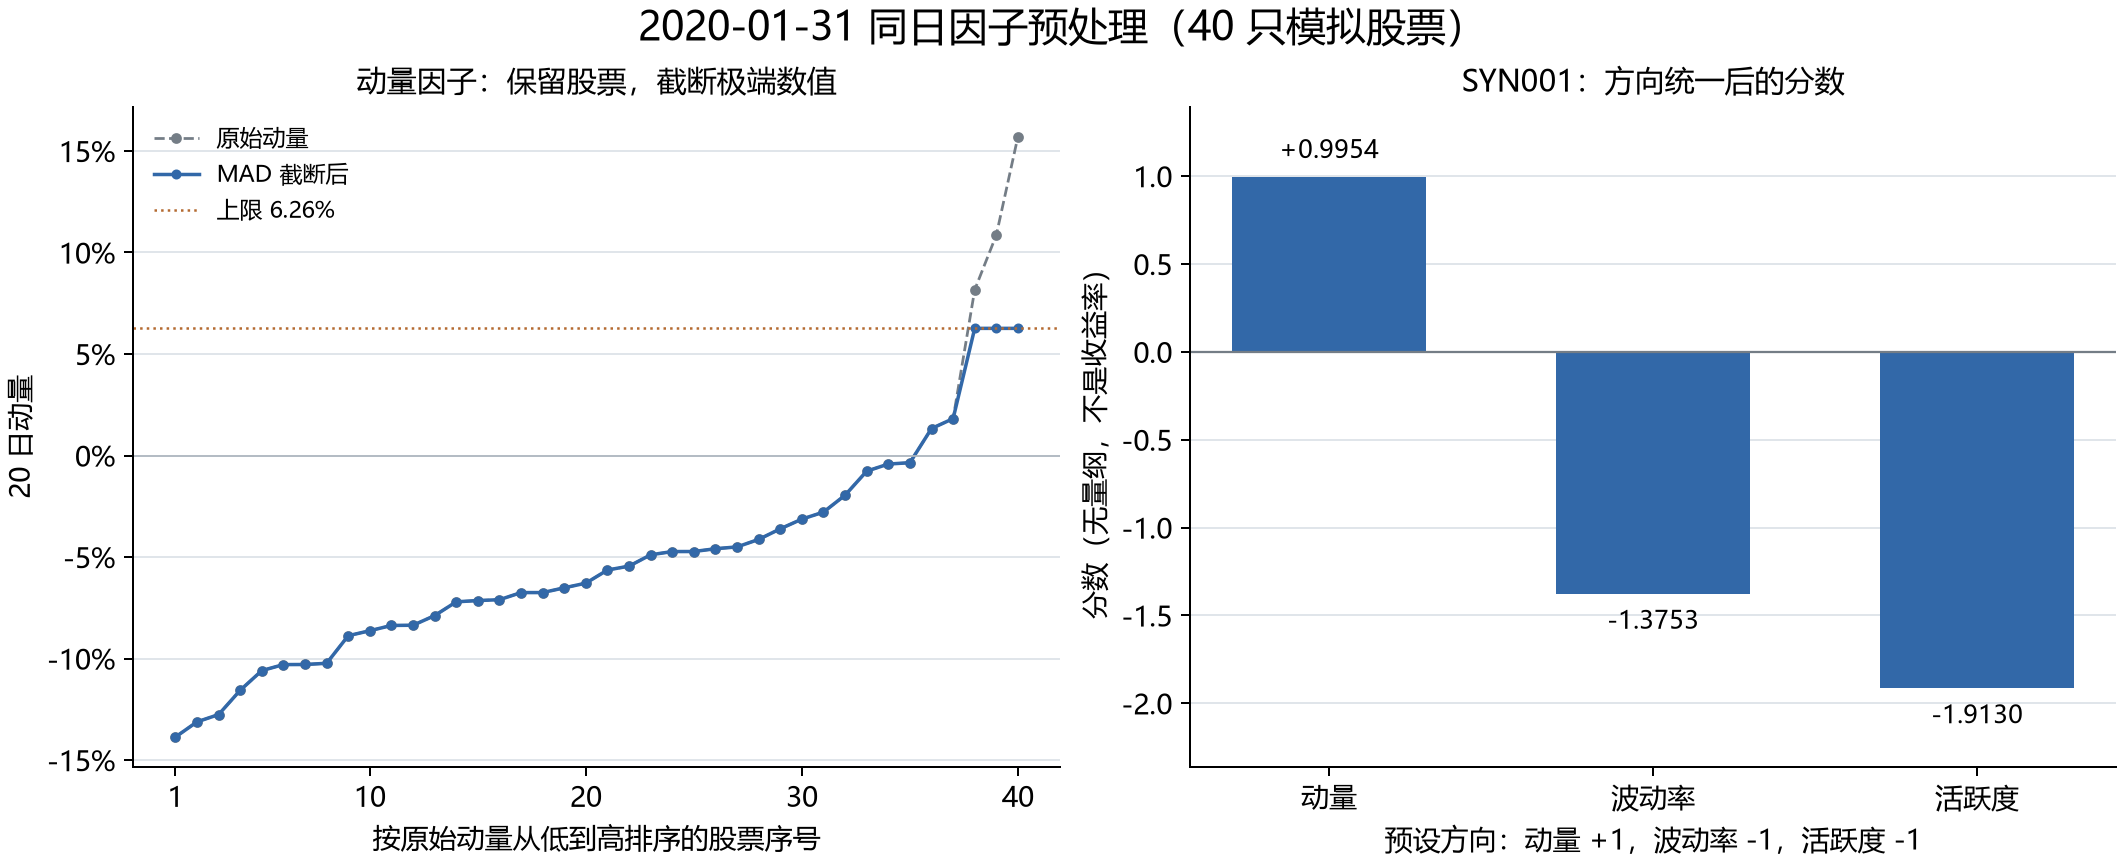

In [6]:
from IPython.display import Image, display
display(Image(filename=str(PROJECT_ROOT / 'runs/first_demo_20261107/lesson11_preprocessing/factor_preprocessing.png')))

## 运行复核

以上实现已在干净内核中按顺序执行；执行状态记录在仓库的 [Notebook 校验记录](../../publication/notebook_validation.json)。代码中的数据身份、费用和成交假设仍然适用，运行成功只验证对应实现。